# 02 · Druggability triage with protein language-model embeddings

Each of the top 15 targets from notebook 01 is embedded with ESM C and compared against a reference panel of proteins with clinical drug history. Two logistic-regression priors (small molecule, antibody) are validated with **family-held-out cross-validation**, so close homologues cannot leak between training and test. The prior is then blended with the patient evidence to re-rank the targets.

**Data:** the precomputed ESM C embedding pack goes in `data/esm_pack/` (not redistributed in this repo; see the README).


In [1]:
# ---------------- SETTINGS ----------------
TARGETS_FILE = "../results/targets_luad.csv" # output of notebook 01
DISEASE      = "luad"             # short name used in the output file name, e.g. "ad", "ibd", "t2d"
TOP_N        = 15                 # number of top targets to carry forward
GENE_COL, SCORE_COL = "gene", "score"

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

DATA, SEED = Path("../data/esm_pack"), 6900
for f in ["panel.tsv", "panel_emb_main.npy", "proteome.tsv", "proteome_emb_main.npy"]:
    if not (DATA / f).exists():
        raise FileNotFoundError(f"{DATA / f} not found. Put the ESM C embedding pack in data/esm_pack/ (see README).")
if not Path(TARGETS_FILE).exists():
    raise FileNotFoundError(f"{TARGETS_FILE} not found. Run notebook 01 first.")

panel = pd.read_csv(DATA / "panel.tsv", sep="\t")
X_panel = np.load(DATA / "panel_emb_main.npy").astype("float32")
proteome = pd.read_csv(DATA / "proteome.tsv", sep="\t")
X_prot = np.load(DATA / "proteome_emb_main.npy").astype("float32")
manifest = json.load(open(DATA / "manifest.json"))
assert len(panel) == len(X_panel) and len(proteome) == len(X_prot), "tables and embeddings are misaligned"
if manifest.get("dry_run"):
    print("*** WARNING: DRY RUN data pack (fake data). Numbers are not real biology. ***")
print(f"Panel {X_panel.shape} | proteome {X_prot.shape} | model: {manifest['embedding_models']['main']['model']}")

# ---- Helper functions (adapted from course lab materials) ----
def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))

def evaluate(X, y, groups, folds=5):
    # Out-of-fold AUROC and average precision for a random split and a family split.
    y = np.asarray(y).astype(int)
    rand = cross_val_predict(make_model(), X, y, cv=StratifiedKFold(folds, shuffle=True, random_state=SEED),
                             method="predict_proba")[:, 1]
    fam = cross_val_predict(make_model(), X, y, cv=GroupKFold(folds), groups=groups, method="predict_proba")[:, 1]
    return pd.DataFrame({"AUROC": [roc_auc_score(y, rand), roc_auc_score(y, fam)],
                         "Average precision": [average_precision_score(y, rand), average_precision_score(y, fam)]},
                        index=["Random split", "Family split"]).round(3)

def fit_prior(X, y):
    # Fit the tractability prior on all rows given; returns a fitted model with .predict_proba().
    return make_model().fit(X, np.asarray(y).astype(int))

def require(**kw):
    # Stops with a clear message if a value is still `...`
    for name, val in kw.items():
        if val is Ellipsis:
            raise NotImplementedError(f"`{name}` is still `...`")

def cosine_matrix(A, B):
    A = A / np.linalg.norm(A, axis=1, keepdims=True)
    B = B / np.linalg.norm(B, axis=1, keepdims=True)
    return A @ B.T

Panel (1201, 960) | proteome (20190, 960) | model: esmc_300m


## Step 1 · Load and map the targets

Keep the top `TOP_N` targets by multi-omics score, then find each gene's row in `proteome.tsv`. **The row number in `proteome.tsv` is the row number in `proteome_emb_main.npy`.** Genes without a reviewed protein (for example non-coding RNAs) will not be found: list them, don't drop them silently.

In [3]:
mine = pd.read_csv(TARGETS_FILE)
mine = mine.rename(columns={GENE_COL: "gene", SCORE_COL: "score"})
mine["gene"] = mine["gene"].astype(str).str.strip().str.upper()
top = mine.sort_values("score", ascending=False).head(TOP_N).reset_index(drop=True)

row_of = {g: i for i, g in enumerate(proteome["gene"])}

# split the top genes into those found in proteome.tsv (mapped) and those not found (unmapped).
#       Then keep only mapped genes in `targets`, with a column `row` giving each gene's row in proteome.tsv.
unmapped = [g for g in top["gene"] if g not in row_of]
targets = top[top["gene"].isin(row_of)].copy()
targets["row"] = targets["gene"].map(row_of)

require(unmapped=unmapped, targets=targets)
targets = targets.reset_index(drop=True)
my_genes = targets["gene"].tolist()
print(f"Top {len(top)} targets: {len(targets)} mapped, {len(unmapped)} unmapped")
print("Unmapped:", unmapped)
targets[["gene", "score", "row"]]

Top 15 targets: 15 mapped, 0 unmapped
Unmapped: []


,gene,score,row
0,FGFR2,0.943723,5799
1,KRT8,0.883117,8740
2,USHBP1,0.880952,18832
3,GIPC2,0.847403,6395
4,CLPTM1L,0.841991,3261
5,BRCA2,0.820346,1693
6,DNAJB4,0.817100,4463
7,CYP1A1,0.812771,3931
8,PALM,0.812771,12202
9,EPHX2,0.807359,5119


## Step 2 · Guard against leakage

Remove **the targets themselves** from the training panel before fitting anything, so no target is predicted using its own label.

In [4]:
# build `keep`, a boolean array that is True for panel proteins that are NOT among the targets.
keep = ~panel["gene"].isin(my_genes)

require(keep=keep)
train, X_train = panel[keep].reset_index(drop=True), X_panel[keep]
print(f"Removed {(~keep).sum()} targets from the training panel; training on {len(train)} proteins.")

Removed 1 targets from the training panel; training on 1200 proteins.


## Step 3 · Validate the prior

Family-split AUROC and average precision on the training panel. This says how far to trust the numbers that follow.

In [5]:
# call evaluate() on the training panel with the any_clinical labels and family groups.
validation = evaluate(X_train, train["any_clinical"], train["family_group"])
require(validation=validation)
print(validation)
print(f"Chance level for average precision = {train['any_clinical'].mean():.3f}")

              AUROC  Average precision
Random split  0.850              0.737
Family split  0.737              0.541
Chance level for average precision = 0.334


## Step 4 · Two priors, by modality

One prior is fit on `sm_clinical` (small molecule) and one on `ab_clinical` (antibody), then both are predicted for the targets using their rows in `X_prot`.

In [6]:
X_targets = X_prot[targets["row"].values]

# fit the two priors on the training panel and add columns p_sm and p_ab to `targets`.
#       Hint: fit_prior(X, y).predict_proba(X_new)[:, 1]
targets["p_sm"] = fit_prior(X_train, train["sm_clinical"]).predict_proba(X_targets)[:, 1]
targets["p_ab"] = fit_prior(X_train, train["ab_clinical"]).predict_proba(X_targets)[:, 1]

require(p_sm=targets["p_sm"].iloc[0], p_ab=targets["p_ab"].iloc[0])
targets[["gene", "score", "p_sm", "p_ab"]].round(3)

,gene,score,p_sm,p_ab
0,FGFR2,0.944,0.864,0.123
1,KRT8,0.883,0.005,0.016
2,USHBP1,0.881,0.005,0.001
3,GIPC2,0.847,0.179,0.001
4,CLPTM1L,0.842,0.389,0.009
5,BRCA2,0.820,0.004,0.002
6,DNAJB4,0.817,0.014,0.002
7,CYP1A1,0.813,0.752,0.000
8,PALM,0.813,0.002,0.010
9,EPHX2,0.807,0.220,0.001


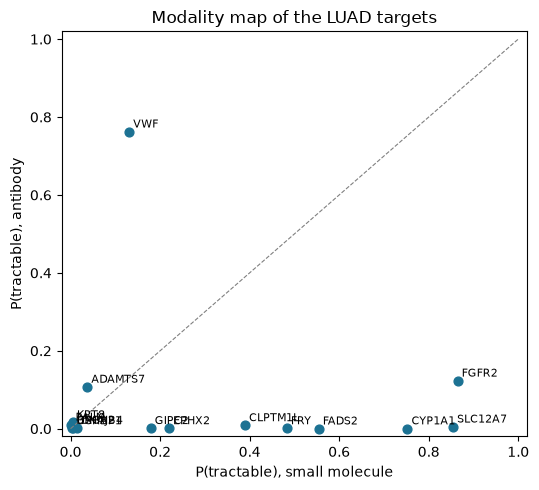

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(targets.p_sm, targets.p_ab, s=40, c="#1C7293")
for _, r in targets.iterrows():
    ax.annotate(r.gene, (r.p_sm, r.p_ab), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=0.8)
ax.set_xlabel("P(tractable), small molecule"); ax.set_ylabel("P(tractable), antibody")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_title("Modality map of the LUAD targets")
plt.tight_layout(); plt.show()

## Step 5 · Nearest known drug targets

For each target, the three most similar training-panel proteins **with clinical precedence**, with cosine similarity. This is the evidence behind each prior.

In [8]:
drugged = train[train["any_clinical"]].reset_index(drop=True)
X_drugged = X_train[train["any_clinical"].values]
S = cosine_matrix(X_targets, X_drugged)          # rows = targets, columns = drugged proteins

# for each target, find the 3 most similar drugged proteins and store them as text
#       like "EGFR (0.81); ERBB2 (0.79); KIT (0.77)" in a new column `nearest_drug_targets`.
#       Hint: np.argsort(-S[i])[:3] gives the column indices of the 3 largest similarities in row i.
def top3(i):
    idx = np.argsort(-S[i])[:3]
    return "; ".join(f"{drugged['gene'].iloc[j]} ({S[i, j]:.2f})" for j in idx)

targets["nearest_drug_targets"] = [top3(i) for i in range(len(targets))]

require(nearest_drug_targets=targets["nearest_drug_targets"].iloc[0])
targets[["gene", "p_sm", "p_ab", "nearest_drug_targets"]].round(2)

,gene,p_sm,p_ab,nearest_drug_targets
0,FGFR2,0.86,0.12,FGFR1 (0.99); GABRG2 (0.95); GABRG3 (0.95)
1,KRT8,0.00,0.02,SNCA (0.89); HSP90AB1 (0.89); HSPA1B (0.89)
2,USHBP1,0.00,0.00,IL4R (0.94); CD248 (0.93); PDCD1 (0.92)
3,GIPC2,0.18,0.00,PDE1B (0.94); EPHB3 (0.93); PRKAB2 (0.92)
4,CLPTM1L,0.39,0.01,ATP1B2 (0.93); ATP1B3 (0.93); GPD2 (0.92)
5,BRCA2,0.00,0.00,PLK4 (0.91); PTHLH (0.91); TTK (0.91)
6,DNAJB4,0.01,0.00,LYN (0.91); TSG101 (0.91); SRC (0.91)
7,CYP1A1,0.75,0.00,CYP17A1 (0.99); ERAP1 (0.94); IDO1 (0.93)
8,PALM,0.00,0.01,PDE4C (0.91); PDE4D (0.90); KCNQ4 (0.88)
9,EPHX2,0.22,0.00,NPEPPS (0.95); MGLL (0.94); DIO1 (0.94)


## Step 6 · Re-rank and export

Combine the multi-omics evidence with the best-modality tractability prior. The weight `w = 0.6` favours the patient data (0 = tractability only, 1 = evidence only), because the prior reflects drug-discovery history rather than measured biology.


In [9]:
w = 0.6    # 60 % patient evidence, 40 % tractability prior

targets["evidence_pct"] = targets["score"].rank(pct=True)
targets["tract"] = targets[["p_sm", "p_ab"]].max(axis=1)

# compute `final` = w * evidence_pct + (1 - w) * (percentile rank of tract), then `rank` (1 = best).
targets["final"] = w * targets["evidence_pct"] + (1 - w) * targets["tract"].rank(pct=True)
targets["rank"] = targets["final"].rank(ascending=False, method="first").astype(int)

require(final=targets["final"].iloc[0], rank=targets["rank"].iloc[0])
out = (targets.rename(columns={"score": "evidence_score"})
       [["rank", "gene", "evidence_score", "p_sm", "p_ab", "nearest_drug_targets", "final"]]
       .sort_values("rank"))
out_file = f"../results/targets_{DISEASE}_reranked.csv"
out.to_csv(out_file, index=False)
print(f"Wrote {out_file} ({len(out)} targets)")
out.round(3)

Wrote ../results/targets_luad_reranked.csv (15 targets)


,rank,gene,evidence_score,p_sm,p_ab,nearest_drug_targets,final
0,1,FGFR2,0.944,0.864,0.123,FGFR1 (0.99); GABRG2 (0.95); GABRG3 (0.95),1.000
1,2,KRT8,0.883,0.005,0.016,SNCA (0.89); HSP90AB1 (0.89); HSPA1B (0.89),0.693
4,3,CLPTM1L,0.842,0.389,0.009,ATP1B2 (0.93); ATP1B3 (0.93); GPD2 (0.92),0.680
3,4,GIPC2,0.847,0.179,0.001,PDE1B (0.94); EPHB3 (0.93); PRKAB2 (0.92),0.667
7,5,CYP1A1,0.813,0.752,0.000,CYP17A1 (0.99); ERAP1 (0.94); IDO1 (0.93),0.640
2,6,USHBP1,0.881,0.005,0.001,IL4R (0.94); CD248 (0.93); PDCD1 (0.92),0.573
11,7,SLC12A7,0.750,0.854,0.005,KCNA2 (0.95); SCN4A (0.95); PDK2 (0.93),0.533
6,8,DNAJB4,0.817,0.014,0.002,LYN (0.91); TSG101 (0.91); SRC (0.91),0.467
10,9,FRY,0.781,0.483,0.001,NCBP1 (0.96); MAP3K1 (0.96); AFP (0.95),0.467
12,10,VWF,0.746,0.131,0.762,PLAT (0.96); MMP9 (0.96); TPO (0.95),0.467


In [10]:
# How did the ranking move?
moved = targets.assign(evidence_rank=targets["score"].rank(ascending=False, method="first").astype(int))
moved["change"] = moved["evidence_rank"] - moved["rank"]
moved.sort_values("change")[["gene", "evidence_rank", "rank", "change", "p_sm", "p_ab"]].round(2)

,gene,evidence_rank,rank,change,p_sm,p_ab
5,BRCA2,6,12,-6,0.00,0.00
8,PALM,9,13,-4,0.00,0.01
2,USHBP1,3,6,-3,0.00,0.00
6,DNAJB4,7,8,-1,0.01,0.00
9,EPHX2,10,11,-1,0.22,0.00
13,ADAMTS7,14,15,-1,0.04,0.11
0,FGFR2,1,1,0,0.86,0.12
1,KRT8,2,2,0,0.00,0.02
3,GIPC2,4,4,0,0.18,0.00
14,FADS2,15,14,1,0.55,0.00
